# Occupations over time
Share of active individuals per occupation over time.

In [1]:
import random
import tempfile
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from style import *

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DB_PATH = '../../data/cultura/cultura_enriched_v3.2.duckdb'

apply_style()

## Parameters

In [2]:
WORLD_RANGE = (-500, 2018)
POLITY_NAMES = ['Roman Empire', 'Tang Dynasty']

TOP_OCCUPATIONS_PER_CENTURY = 10
MAX_OCCUPATIONS_PER_SCOPE = 20
BUCKET_YEARS = 50

## Load data
### Occupations per individual

In [3]:
con = duckdb.connect(DB_PATH, read_only=True)
con.sql(f"SET memory_limit='6GB'; SET threads=4; SET temp_directory='{tempfile.mkdtemp()}';")

con.sql("""
    CREATE TEMP TABLE people AS
    SELECT entity.qid           AS qid,
           start_of_active_life.year AS active_life_start,
           end_of_active_life.year  AS active_life_end
    FROM   individual_enriched
    WHERE  start_of_active_life.year IS NOT NULL AND end_of_active_life.year IS NOT NULL
""")

con.sql("""
    CREATE TEMP TABLE individual_occupation AS
    SELECT entity.qid                    AS qid,
           unnest(occupation).entity.qid AS occupation_qid
    FROM   individual
    WHERE  len(occupation) > 0
""")

con.sql("""
    CREATE TEMP TABLE occupation_rows AS
    SELECT DISTINCT
           'World'                    AS scope,
           people.qid                 AS qid,
           people.active_life_start          AS active_life_start,
           people.active_life_end            AS active_life_end,
           occupation.entity.label_en AS occupation
    FROM   people
    JOIN   individual_occupation USING (qid)
    JOIN   occupation ON occupation.entity.qid = individual_occupation.occupation_qid
    WHERE  occupation.entity.label_en IS NOT NULL
""")

world_overview = con.sql("""
    SELECT COUNT(*)            AS occupation_rows,
           COUNT(DISTINCT qid) AS individuals,
           MIN(active_life_start)     AS min_start,
           MAX(active_life_end)       AS max_end
    FROM   occupation_rows
    WHERE  scope = 'World'
""").pl()
world_overview

occupation_rows,individuals,min_start,max_end
i64,i64,i64,i64
5930755,3501286,-4160,20160701


### Polity year spans

In [4]:
polity_year_spans = con.sql("""
    SELECT   name                      AS polity_name,
             MIN(territory.start_year) AS polity_start,
             MAX(territory.end_year)   AS polity_end
    FROM     polity, unnest(territories) AS unnested(territory)
    WHERE    list_contains($names, name)
    GROUP BY name
    ORDER BY name
""", params={'names': POLITY_NAMES}).pl()

assert polity_year_spans.height == len(POLITY_NAMES)
polity_to_year_range = {
    row['polity_name']: ((row['polity_start'] // 100) * 100, ((row['polity_end'] + 99) // 100) * 100 - 1)
    for row in polity_year_spans.iter_rows(named=True)
}
ROMAN_RANGE = polity_to_year_range['Roman Empire']
TANG_RANGE = polity_to_year_range['Tang Dynasty']
print('ROMAN_RANGE:', ROMAN_RANGE, ' TANG_RANGE:', TANG_RANGE)
polity_year_spans

ROMAN_RANGE: (-100, 399)  TANG_RANGE: (600, 999)


polity_name,polity_start,polity_end
str,i64,i64
"""Roman Empire""",-31,394
"""Tang Dynasty""",623,910


### Polity cohorts
An individual belongs to a polity when it is one of their active-life polities (`active_life_polity`, `cultura_enriched_v3.2`).

In [5]:
con.sql("""
    CREATE TEMP TABLE individual_polity AS
    SELECT entity.qid                 AS qid,
           unnest(list_transform(active_life_polity, stage_match -> stage_match.polity.name)) AS polity_name
    FROM   individual_enriched
""")

con.sql("""
    INSERT INTO occupation_rows
    SELECT DISTINCT
           individual_polity.polity_name AS scope,
           occupation_rows.qid,
           occupation_rows.active_life_start,
           occupation_rows.active_life_end,
           occupation_rows.occupation
    FROM   occupation_rows
    JOIN   individual_polity USING (qid)
    WHERE  occupation_rows.scope = 'World'
      AND  list_contains($names, individual_polity.polity_name)
""", params={'names': POLITY_NAMES})

OCCUPATION_ROWS_OF_SCOPE = """
    SELECT qid, active_life_start, active_life_end, occupation
    FROM   occupation_rows
    WHERE  scope = $scope
"""
occupation_rows_roman = con.sql(OCCUPATION_ROWS_OF_SCOPE, params={'scope': 'Roman Empire'}).pl()
occupation_rows_tang = con.sql(OCCUPATION_ROWS_OF_SCOPE, params={'scope': 'Tang Dynasty'}).pl()

for name, rows in [('Roman Empire', occupation_rows_roman), ('Tang Dynasty', occupation_rows_tang)]:
    print(f'{name:13s}: {rows.height:,} occupation rows, {rows["qid"].n_unique():,} individuals')
occupation_rows_tang.head()

Roman Empire : 3,104 occupation rows, 1,960 individuals
Tang Dynasty : 2,578 occupation rows, 1,992 individuals


qid,active_life_start,active_life_end,occupation
str,i64,i64,str
"""Q5433802""",678,698,"""poet"""
"""Q15922438""",736,746,"""poet"""
"""Q45542150""",757,773,"""bureaucrat"""
"""Q711640""",651,666,"""poet"""
"""Q8070526""",864,884,"""military personnel"""


## Preprocessing
### Top occupations per scope

In [6]:
def top_occupations(scope, year_range):
    lo, hi = year_range
    con.sql("""
        CREATE OR REPLACE TEMP TABLE century_ranks AS
        SELECT   CAST(floor(active_life_start / 100) * 100 AS BIGINT) AS century,
                 occupation,
                 COUNT(*) AS n,
                 row_number() OVER (PARTITION BY century ORDER BY COUNT(*) DESC, occupation) AS rank_in_century
        FROM     occupation_rows
        WHERE    scope = $scope
          AND    active_life_start BETWEEN $lo AND $hi
        GROUP BY century, occupation
    """, params={'scope': scope, 'lo': lo, 'hi': hi})

    return con.sql("""
        SELECT   occupation,
                 CAST(SUM(n) AS BIGINT) AS total_individuals,
                 MIN(rank_in_century)   AS best_rank
        FROM     century_ranks
        WHERE    rank_in_century <= $top
        GROUP BY occupation
        ORDER BY total_individuals DESC, best_rank, occupation
        LIMIT    $limit
    """, params={'top': TOP_OCCUPATIONS_PER_CENTURY, 'limit': MAX_OCCUPATIONS_PER_SCOPE}).pl()

world_top = top_occupations('World', WORLD_RANGE)
roman_top = top_occupations('Roman Empire', ROMAN_RANGE)
tang_top = top_occupations('Tang Dynasty', TANG_RANGE)

for name, top in [('world', world_top), ('roman', roman_top), ('tang', tang_top)]:
    assert top['occupation'].is_unique
    print(f'{name}: {top.height} occupations')
world_top.head(10)

world: 20 occupations
roman: 20 occupations
tang: 18 occupations


occupation,total_individuals,best_rank
str,i64,i64
"""politician""",574110,1
"""writer""",262092,2
"""painter""",175130,2
"""university teacher""",158703,3
"""journalist""",103854,6
"""actor""",102746,5
"""military personnel""",82402,2
"""poet""",78495,1
"""association football player""",64606,7


### Active individuals per year

In [7]:
def active_per_year(scope, top, year_range):
    lo, hi = year_range
    order = top['occupation'].to_list() + ['Other']
    spans = con.sql("""
        SELECT   CASE WHEN list_contains($top, occupation) THEN occupation ELSE 'Other' END AS occupation_group,
                 greatest(active_life_start, $lo) AS active_start,
                 least(active_life_end, $hi)      AS active_end,
                 COUNT(*)                  AS row_count
        FROM     occupation_rows
        WHERE    scope = $scope
          AND    greatest(active_life_start, $lo) <= least(active_life_end, $hi)
        GROUP BY occupation_group, active_start, active_end
    """, params={'scope': scope, 'top': order[:-1], 'lo': lo, 'hi': hi}).pl()

    years = np.arange(lo, hi + 2)
    counts = {}
    for occupation in order:
        s = spans.filter(pl.col('occupation_group') == occupation)
        delta = np.zeros(len(years), dtype=np.int64)
        np.add.at(delta, s['active_start'].to_numpy() - lo, s['row_count'].to_numpy())
        np.add.at(delta, s['active_end'].to_numpy() + 1 - lo, -s['row_count'].to_numpy())
        counts[occupation] = np.cumsum(delta)[:-1]
    return pl.DataFrame({'year': years[:-1], **counts}), order

world_active, world_order = active_per_year('World', world_top, WORLD_RANGE)
roman_active, roman_order = active_per_year('Roman Empire', roman_top, ROMAN_RANGE)
tang_active, tang_order = active_per_year('Tang Dynasty', tang_top, TANG_RANGE)

con.close()

assert (world_active.drop('year').to_numpy() >= 0).all()
print('world shape:', world_active.shape)
world_active.head()

world shape: (2519, 22)


year,politician,writer,painter,university teacher,journalist,actor,military personnel,poet,association football player,historian,researcher,Catholic priest,physician,lawyer,Catholic bishop,film director,screenwriter,teacher,architect,pensioner,Other
i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64
-500,35,7,1,0,0,0,31,1,0,2,0,0,0,0,0,0,0,1,0,0,73
-499,34,6,1,0,0,0,30,1,0,2,0,0,0,0,0,0,0,1,0,0,76
-498,36,3,1,0,0,0,31,0,0,1,0,0,0,0,0,0,0,1,0,0,73
-497,35,5,1,0,0,0,31,1,0,1,0,0,0,0,0,0,0,1,0,0,78
-496,32,5,1,0,0,0,32,1,0,1,0,0,0,0,0,0,0,1,0,0,78


### Occupation shares per 50-year bucket

In [8]:
def bucket_shares(active, order):
    lo, hi = active['year'].min(), active['year'].max()
    bucketed = (
        active
        .with_columns(((pl.col('year') - lo) // BUCKET_YEARS * BUCKET_YEARS + lo).alias('bucket'))
        .group_by('bucket').agg(pl.len().alias('n_years'), *[pl.col(o).mean() for o in order])
        .sort('bucket')
    )
    complete = bucketed.filter(pl.col('n_years') == BUCKET_YEARS)
    print(f'buckets: {bucketed.height} -> {complete.height} complete ({complete["bucket"].min()}–{complete["bucket"].max() + BUCKET_YEARS - 1})')
    total = pl.sum_horizontal(order)
    return (complete.with_columns(total.alias('total'))
                    .filter(pl.col('total') > 0)
                    .with_columns([(pl.col(o) / pl.col('total')).alias(o) for o in order]))

world_shares = bucket_shares(world_active, world_order)
roman_shares = bucket_shares(roman_active, roman_order)
tang_shares = bucket_shares(tang_active, tang_order)

assert np.allclose(world_shares.select(world_order).to_numpy().sum(axis=1), 1)
world_shares.head()

buckets: 51 -> 50 complete (-500–1999)
buckets: 10 -> 10 complete (-100–399)
buckets: 8 -> 8 complete (600–999)


bucket,n_years,politician,writer,painter,university teacher,journalist,actor,military personnel,poet,association football player,historian,researcher,Catholic priest,physician,lawyer,Catholic bishop,film director,screenwriter,teacher,architect,pensioner,Other,total
i64,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
-500,50,0.233724,0.040437,0.001348,0.0,0.0,0.0,0.193961,0.02224,0.0,0.003505,0.0,0.0,0.000135,0.0,0.0,0.0,0.0,0.000944,0.003235,0.0,0.500472,148.38
-450,50,0.215734,0.041775,0.002592,0.0,0.0,0.0,0.225492,0.018448,0.0,0.011282,0.0,0.0,0.007318,0.0,0.0,0.0,0.0,0.003049,0.005489,0.0,0.468821,131.18
-400,50,0.189523,0.052085,0.002409,0.0,0.0,0.0,0.193437,0.023032,0.0,0.022129,0.0,0.0,0.006925,0.001355,0.0,0.0,0.0,0.0,0.003312,0.0,0.505796,132.86
-350,50,0.145196,0.045001,0.005097,0.0,0.0,0.0,0.197679,0.014964,0.0,0.02841,0.0,0.0,0.005205,0.001518,0.0,0.0,0.0,0.004988,0.005205,0.0,0.546736,184.44
-300,50,0.204287,0.047053,0.0,0.0,0.0,0.0,0.16209,0.039183,0.0,0.026792,0.0,0.0,0.012224,0.0,0.0,0.0,0.0,0.0,0.00134,0.0,0.507033,119.44


### Shared occupation palette

In [9]:
all_occupations = list(dict.fromkeys(world_order[:-1] + roman_order[:-1] + tang_order[:-1]))
occupation_palette = categorical_palette(all_occupations)
occupation_palette['Other'] = OTHER_CATEGORY_COLOR
print(f'shared palette: {len(all_occupations)} occupations + Other')

shared palette: 42 occupations + Other


In [10]:
def format_year(year):
    year = int(round(year))
    return f'{abs(year)} BCE' if year < 0 else f'{year}'


def plot_share_area(shares, order, scope_name, log_time=False, ref_year=2020, tick_years=None):
    mids = shares['bucket'].to_numpy() + BUCKET_YEARS / 2
    x = -np.log10(ref_year - mids) if log_time else mids
    if tick_years is None:
        tick_years = shares['bucket'].to_list()
    ticks = [-np.log10(ref_year - y) for y in tick_years] if log_time else tick_years

    fig, ax = plt.subplots(figsize=(16, 7.5))
    ax.stackplot(x, shares.select(order).to_numpy().T, labels=order,
                 colors=[occupation_palette[o] for o in order], edgecolor=BACKGROUND_COLOR, linewidth=0.2, alpha=0.9)
    ax.set_xticks(ticks)
    ax.set_xticklabels([format_year(y) for y in tick_years], rotation=30, ha='right')
    ax.set_xlim(x.min(), x.max())
    ax.set_ylim(0, 1)
    ax.set_xlabel('Year (log time)' if log_time else 'Year')
    fig.suptitle(scope_name, fontsize=POLITY_TITLE_FONTSIZE, y=0.98)
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles[::-1], labels[::-1], loc='upper left', bbox_to_anchor=(1.01, 1.0),
              borderaxespad=0, handlelength=1.2, labelspacing=0.4)
    fig.subplots_adjust(left=0.06, right=0.78, top=0.91, bottom=0.16)
    plt.show()

## Figures
### Figure S3A: World

#### Data plotted

In [11]:
world_plotted = world_shares.select('bucket', *world_order)
print('shape:', world_plotted.shape)
world_plotted

shape: (50, 22)


bucket,politician,writer,painter,university teacher,journalist,actor,military personnel,poet,association football player,historian,researcher,Catholic priest,physician,lawyer,Catholic bishop,film director,screenwriter,teacher,architect,pensioner,Other
i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
-500,0.233724,0.040437,0.001348,0.0,0.0,0.0,0.193961,0.02224,0.0,0.003505,0.0,0.0,0.000135,0.0,0.0,0.0,0.0,0.000944,0.003235,0.0,0.500472
-450,0.215734,0.041775,0.002592,0.0,0.0,0.0,0.225492,0.018448,0.0,0.011282,0.0,0.0,0.007318,0.0,0.0,0.0,0.0,0.003049,0.005489,0.0,0.468821
-400,0.189523,0.052085,0.002409,0.0,0.0,0.0,0.193437,0.023032,0.0,0.022129,0.0,0.0,0.006925,0.001355,0.0,0.0,0.0,0.0,0.003312,0.0,0.505796
-350,0.145196,0.045001,0.005097,0.0,0.0,0.0,0.197679,0.014964,0.0,0.02841,0.0,0.0,0.005205,0.001518,0.0,0.0,0.0,0.004988,0.005205,0.0,0.546736
-300,0.204287,0.047053,0.0,0.0,0.0,0.0,0.16209,0.039183,0.0,0.026792,0.0,0.0,0.012224,0.0,0.0,0.0,0.0,0.0,0.00134,0.0,0.507033
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
1750,0.064471,0.051503,0.055231,0.012949,0.003906,0.007546,0.020764,0.021857,0.000007,0.012761,0.000068,0.026613,0.020026,0.0082,0.015159,0.000011,0.000094,0.009021,0.018571,0.0,0.65124
1800,0.102582,0.053831,0.056379,0.013577,0.009247,0.008194,0.02407,0.021354,0.000009,0.011631,0.000101,0.014016,0.021755,0.01622,0.007048,0.000015,0.000046,0.012419,0.015091,0.000004,0.612411
1850,0.107716,0.059353,0.053552,0.017074,0.02161,0.009225,0.013778,0.017184,0.000317,0.013962,0.000201,0.011859,0.02109,0.020438,0.004167,0.0002,0.000287,0.018047,0.01948,0.000004,0.590456


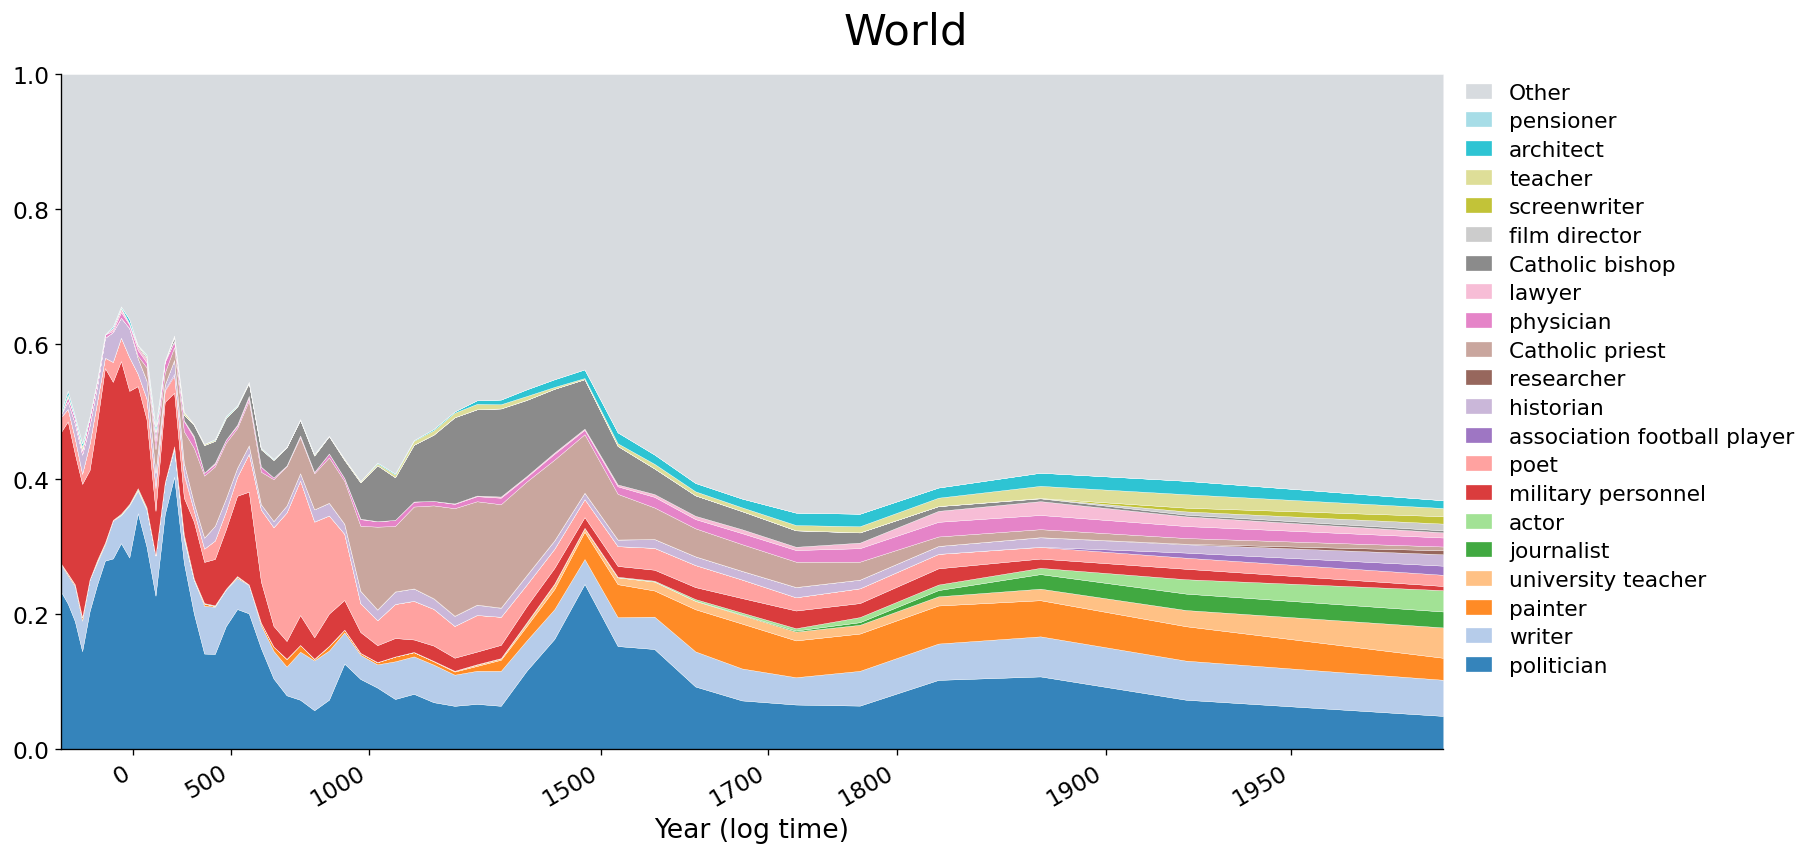

In [12]:
plot_share_area(world_plotted, world_order, 'World', log_time=True,
                tick_years=[0, 500, 1000, 1500, 1700, 1800, 1900, 1950])

### Figure S3B: Roman Empire

#### Data plotted

In [13]:
roman_plotted = roman_shares.select('bucket', *roman_order)
print('shape:', roman_plotted.shape)
roman_plotted

shape: (10, 22)


bucket,politician,military personnel,writer,Catholic priest,presbyter,philosopher,military officer,soldier,poet,historian,Catholic bishop,monarch,monk,theologian,priest,ancient Roman senator,orator,rhetorician,aristocrat,elegist,Other
i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
-100,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
-50,0.275954,0.214262,0.112438,0.0,0.0,0.030846,0.002985,0.00398,0.067993,0.049751,0.0,0.009287,0.0,0.0,0.000995,0.0,0.025871,0.01791,0.002985,0.002322,0.182421
0,0.357188,0.218915,0.048554,0.005911,0.008866,0.020477,0.005489,0.013933,0.02301,0.031243,0.003589,0.008866,0.0,0.001267,0.009711,0.008866,0.002322,0.009077,0.017522,0.0,0.205193
50,0.315612,0.157103,0.059916,0.024895,0.053586,0.02827,0.016878,0.014065,0.029395,0.028973,0.003235,0.006329,0.00211,0.008579,0.007595,0.002672,0.004923,0.002813,0.00211,0.0,0.230942
100,0.234649,0.089035,0.06557,0.041886,0.037939,0.064254,0.015351,0.023684,0.030482,0.018421,0.005482,0.008772,0.00636,0.018202,0.02193,0.017982,0.006798,0.006798,0.006579,0.0,0.279825
150,0.266317,0.136255,0.072415,0.032158,0.03859,0.08647,0.028109,0.021677,0.017866,0.004526,0.0,0.007384,0.000238,0.017389,0.022868,0.010958,0.002859,0.006908,0.000238,0.0,0.226775
200,0.264218,0.078199,0.081754,0.054502,0.037618,0.048578,0.010071,0.01718,0.009182,0.03673,0.015403,0.043839,0.0,0.029028,0.017773,0.003555,0.031991,0.000296,0.0,0.0,0.220083
250,0.115482,0.087946,0.056196,0.08036,0.09188,0.040742,0.032593,0.06603,0.00871,0.016859,0.015454,0.053667,0.013206,0.019387,0.02023,0.0,0.000281,0.006462,0.0,0.0,0.274515
300,0.119528,0.052995,0.065668,0.145449,0.116071,0.031106,0.019297,0.013537,0.016129,0.005472,0.03053,0.013825,0.027362,0.031106,0.026786,0.000288,0.0,0.015265,0.001152,0.0,0.268433


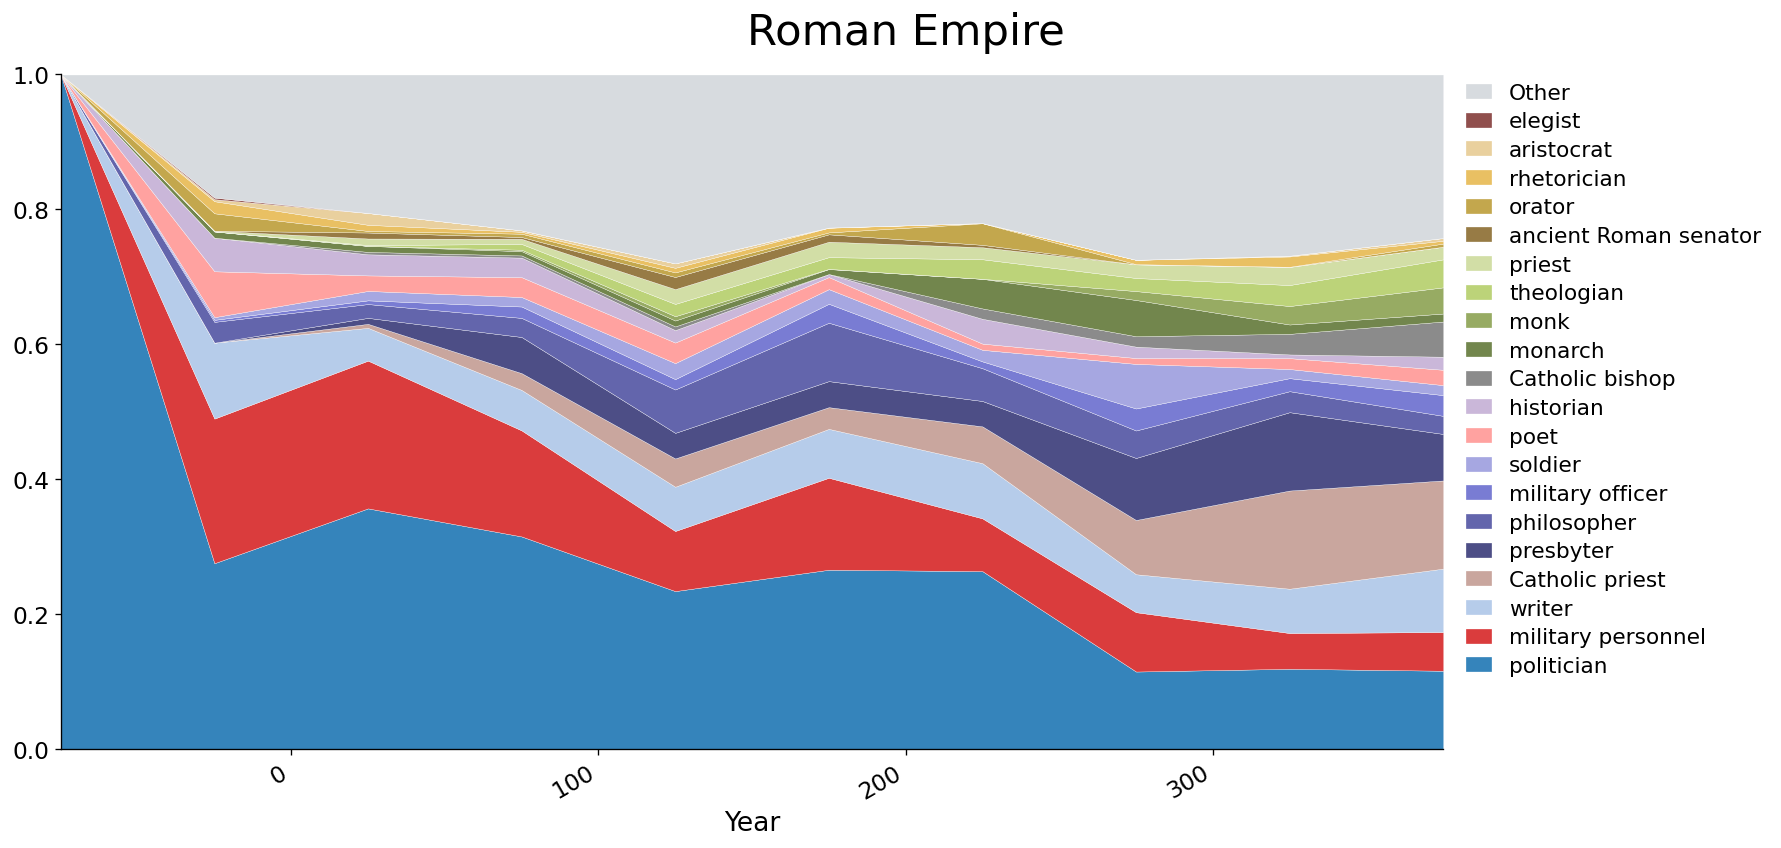

In [14]:
plot_share_area(roman_plotted, roman_order, 'Roman Empire',
                tick_years=list(range(ROMAN_RANGE[0], ROMAN_RANGE[1] + 1, 100)))

### Figure S3C: Tang Dynasty

#### Data plotted

In [15]:
tang_plotted = tang_shares.select('bucket', *tang_order)
print('shape:', tang_plotted.shape)
tang_plotted

shape: (7, 20)


bucket,poet,politician,military personnel,writer,calligrapher,painter,Buddhist monk,official,military leader,historian,eunuch,aristocrat,bureaucrat,diplomat,military commander,monarch,ruler,military officer,Other
i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
600,0.13174,0.404838,0.125911,0.01195,0.053046,0.018945,0.036724,0.0,0.025066,0.024483,0.0,0.000583,0.004955,0.012241,0.002915,0.0,0.0,0.0,0.146604
650,0.280027,0.287618,0.053981,0.054825,0.067982,0.032051,0.03863,0.004386,0.035425,0.012146,0.000337,0.010459,0.002699,0.00253,0.003036,0.004217,0.003205,0.003205,0.103239
700,0.435249,0.183908,0.058365,0.063346,0.064112,0.044955,0.02567,0.018263,0.021328,0.007024,0.005747,0.004853,0.009962,0.006769,0.001277,0.001405,0.001533,0.004342,0.04189
750,0.422763,0.142537,0.084553,0.116686,0.072256,0.030159,0.019567,0.022799,0.000628,0.004667,0.002423,0.0,0.007181,0.00745,0.001526,0.0,0.003142,0.002513,0.059151
800,0.470582,0.162029,0.093439,0.097341,0.087381,0.006674,0.010371,0.00154,0.003183,0.009139,0.006777,0.0,0.003594,0.002362,0.0,0.000821,0.001643,0.001129,0.041996
850,0.395138,0.190658,0.114752,0.100334,0.053146,0.029552,0.003932,0.01275,0.017755,0.016206,0.016444,0.0,0.003337,0.0,0.000596,0.004528,0.001192,0.01001,0.029671
900,0.138663,0.299458,0.093948,0.028455,0.032069,0.017615,0.004065,0.11879,0.017164,0.0,0.012195,0.0,0.003162,0.009485,0.073622,0.01626,0.030714,0.058717,0.045619


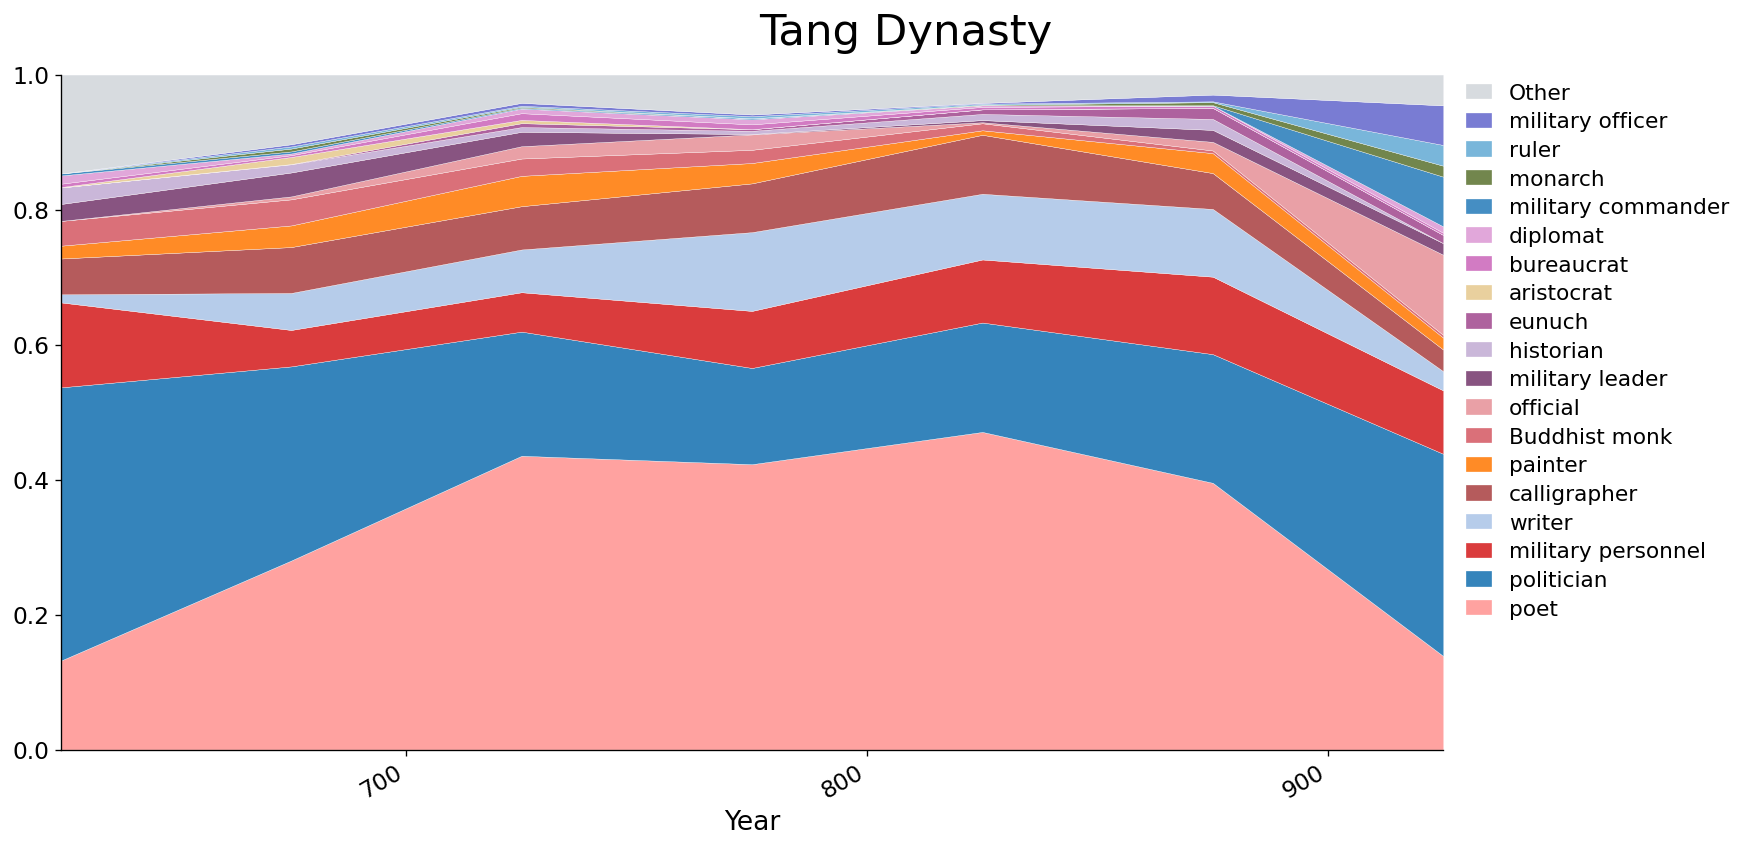

In [16]:
plot_share_area(tang_plotted, tang_order, 'Tang Dynasty',
                tick_years=list(range(TANG_RANGE[0], TANG_RANGE[1] + 1, 100)))